# DX603 — Final Project: Classification

### Due Date: Sunday, December 6th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**

### What We Will Do in This Final Project Submission

This is the second and final stage of your machine learning project. You will have **three weeks** to build on your Project Milestone, improve one advanced model, and evaluate its results.

You will continue with the **Hotel Booking Demand dataset** and the **original training, validation, and test partitions** from your Milestone, and predict whether a reservation will be canceled (`is_canceled = 1`). **F1 for the cancellation class at threshold 0.5** remains the primary metric for comparing models during development. You will also report **accuracy, precision, recall, and ROC AUC** to understand different aspects of performance.

You will complete five problems:

1. **Carry forward your baseline:** Reuse your Milestone cleaning, preprocessing, and Logistic Regression baseline, correcting identified problems.
2. **Review your Milestone models:** Present your existing Logistic Regression, Random Forest, and neural-network comparisons. Revisit your complexity experiment, selected advanced model family, and proposed investigation. **Do not retrain discarded models merely to supply additional metrics.**
3. **Improve your selected model:** Conduct two feature, preprocessing, or class-imbalance experiments and a systematic tuning study. Evaluate the selected family's experiments using multiple classification metrics.
4. **Evaluate a business decision and your final model:** Choose the final model from development evidence, select a **business decision threshold using development data only**, then evaluate the frozen model and threshold once on the held-out test set. Examine the confusion matrix, ROC and precision–recall curves, subgroup errors, and feature importance.
5. **Reflect:** Interpret model performance, business decisions, differences between development and test results, and limitations.

The goal is to **demonstrate sound experimental methodology, make defensible decisions, and interpret results critically**. Experiments can earn full credit even without improvements.

### Points

| Problem | Points |
|---|---:|
| 1. Carry Forward Milestone Baseline | 15 |
| 2. Review Milestone Results and Plan Investigation | 20 |
| 3. Improve Selected Model | 75 |
| 4. Model Evaluation and Interpretation | 50 |
| 5. Reflections and Conclusions | 20 |
| **Total** | **180** |


### Submission and Grading Instructions

- **Submit one executed and saved Jupyter notebook (`.ipynb`)** containing code, saved results, plots, and reflections. There is **no separate report**; this supersedes the earlier Milestone preview.
- Keep your **original Milestone 80% training / 10% validation / 10% test partitions** and justified cleaning and feature-availability decisions. Do not replace the original common validation split. **Do not use the test set for model training, tuning, selection, or evaluation before Problem 4, Part B.** Reporting partition sizes and class proportions in Problem 1A is permitted.
- Use the provided code/results cells, adding cells within problems as needed. Do not delete provided cells or change their headings. Put results in designated results cells and reflections in their designated Markdown cells.
- **Run the notebook and save visible outputs**. Grading uses saved code, results, and explanations; submitted code will not be executed during grading.

Use **cancellation (`1`)** as the positive class. Unless explicitly instructed otherwise, use **threshold 0.5** for the baseline, Milestone comparisons, and **Problem 3 model development**, with **F1 as the primary model-selection metric**. Report **accuracy, precision, recall, F1, and ROC AUC** for your selected-family experiments and final model. Compute ROC AUC and curves from **predicted probabilities**, not class labels. In **Problem 4A**, choose a *separate business decision threshold* from development-only probabilities; freeze it before testing. Explain when reported metrics use 0.5 versus your business threshold.

You may choose your Python variable names, provided the required results are clearly labeled.


## Problem 1 — Carry Forward Your Milestone Baseline [15 points]

Bring forward the essential work from your **Hotel Booking Milestone**, including data preparation, train/validation/test partitions, preprocessing, and the Logistic Regression baseline. The Final Project is a continuation of the Milestone, but your submission must be a **stand-alone, fully executable notebook** that preserves the relevant earlier work and incorporates your new experiments, results, and conclusions. You do not need to repeat the Milestone's exploratory data analysis (EDA).

Reuse Milestone code wherever possible; explain substantive corrections. Preserve the **same observations and original stratified training/validation/test split** unless a justified correction requires otherwise. Do not evaluate on the held-out test set in this problem.

**Important — Preventing Target Leakage**

For this final phase of the project, assume that predictions are made **when a reservation is first booked**. Some features contain information that would not be available at that time and must be excluded from the predictors.

**Remove the following columns from your predictor set:**

- `reservation_status` — directly reveals whether the reservation was canceled.
- `reservation_status_date` — contains information about the eventual reservation outcome.
- `assigned_room_type` — may reflect room assignments made after booking.
- `booking_changes` — records changes made after the original reservation.

These exclusions are **required**, even if you retained these features in your Milestone. 

If these changes affect your Milestone models, update the relevant results as necessary to ensure that your subsequent experiments use valid predictors.

Finally, remember that **identical rows do not necessarily represent erroneous duplicate reservations.** Preserve and document your Milestone decisions about duplicate records unless you have a justified reason to revise them.

### Part A — Data and Preprocessing [4 points]

1. Load the same Hotel Booking dataset and reproduce your Milestone row-level cleaning, feature exclusions, and predictor definitions, incorporating the mandatory feature exclusions specified above. Document any corrections to your Milestone work. In particular, preserve your justified decision about repeated booking records rather than automatically dropping all identical rows.
2. Recreate the original 80% training / 10% validation / 10% test partitions, using the same observations, random seed, and target stratification as in the Milestone. Removing excluded predictor columns should not change which observations belong to each partition.
3. Reconstruct your scikit-learn preprocessing workflow using `Pipeline` and `ColumnTransformer`. Handle missing data and categorical predictors, including numeric-looking category codes, appropriately.
4. Save an **unfitted** version of this workflow as `preprocessor`; it will be fitted inside the baseline pipeline in Part B.
5. Briefly summarize your decisions in comments or Markdown.

**Required output:** Display training, validation, and test sample counts and the cancellation rate in each partition (without evaluating a model on the test set).


In [1]:
# Reuse your Milestone Hotel Booking data cleaning and split code.
# Preserve the original stratified 80/10/10 observations and seed.
# Reconstruct your preprocessing Pipeline/ColumnTransformer as `preprocessor`.
# Do not fit `preprocessor` yet, and do not inspect test model performance.
# Explain substantive differences from the Milestone, if any.

# YOUR CODE HERE

# Imports used throughout the project
import os
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import requests

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Load the same Hotel Booking dataset used in the Milestone
hotel_url = (
    "https://raw.githubusercontent.com/aaqibqadeer/"
    "Hotel-booking-demand/master/hotel_bookings.csv"
)
hotel_file = "hotel_bookings.csv"

if not os.path.exists(hotel_file):
    response = requests.get(hotel_url, timeout=120)
    response.raise_for_status()
    with open(hotel_file, "wb") as file:
        file.write(response.content)

df_hotel = pd.read_csv(hotel_file)

# Repeat the same row cleaning from the Milestone
hotel_clean = df_hotel.copy()

total_guests = (
    hotel_clean["adults"]
    + hotel_clean["children"].fillna(0)
    + hotel_clean["babies"]
)

hotel_clean = hotel_clean[total_guests > 0].copy()
hotel_clean = hotel_clean[hotel_clean["adr"] >= 0].copy()

# Keep identical rows because separate reservations can share the same details.
# These are the same exclusions used in the submitted Milestone.
removed_columns = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list",
    "agent",
    "company"
]

X = hotel_clean.drop(columns=["is_canceled"] + removed_columns)
y = hotel_clean["is_canceled"]

# Recreate the same stratified 80%/10%/10% split using seed 42
X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=0.10,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_development,
    y_development,
    test_size=1/9,
    random_state=42,
    stratify=y_development
)

numerical_columns = X_train.select_dtypes(
    include="number"
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10,
        sparse_output=True
    ))
])

# Leave this unfitted. It will be fitted inside baseline_model.
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])


In [2]:
# REQUIRED SAVED OUTPUT — Part A Results
# Display training, validation, and test sample counts,
# and the cancellation rate (class 1) in each partition.
# Generate these summaries from your actual data partitions.

# YOUR CODE HERE
partition_summary = pd.DataFrame({
    "Partition": ["Training", "Validation", "Test"],
    "Sample Count": [len(X_train), len(X_val), len(X_test)],
    "Cancellation Rate": [y_train.mean(), y_val.mean(), y_test.mean()]
})

display(partition_summary.round(4))



,Partition,Sample Count,Cancellation Rate
0,Training,95367,0.3708
1,Validation,11921,0.3708
2,Test,11921,0.3708


### Part B — Logistic Regression Baseline [5 points]

1. Construct a scikit-learn `Pipeline` combining your unfitted `preprocessor` and `LogisticRegression` (with appropriate convergence settings).
2. Fit on `X_train`, `y_train` **only**, and save the fitted pipeline as `baseline_model`.
3. Report the number of original predictor columns and the number of features after preprocessing (including one-hot encoding).

Reuse your Milestone Logistic Regression baseline implementation, incorporating the required feature exclusions from Part A. Do not tune the baseline or introduce additional modeling changes.

**Required output:** Display the predictor count before and after encoding and other preprocessing.


In [3]:
# Reuse your Milestone Logistic Regression baseline.
# Combine `preprocessor` and LogisticRegression in a fitted Pipeline.
# Fit the pipeline on X_train / y_train only.
# Save it as `baseline_model`.

# YOUR CODE HERE
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

baseline_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['hotel','lead_time','arrival_date_year',...,'adr', 'required_car_parking_spaces','total_of_special_requests']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dro

In [4]:
# REQUIRED SAVED OUTPUT — Part B Results
# Display original predictor count and feature count after preprocessing.
# Compute the latter from the fitted pipeline's transformed features.

# YOUR CODE HERE
original_predictor_count = X_train.shape[1]

encoded_feature_count = baseline_model.named_steps[
    "preprocessor"
].transform(X_train.iloc[:1]).shape[1]

print("Original predictor count:", original_predictor_count)
print("Feature count after preprocessing:", encoded_feature_count)


Original predictor count: 24
Feature count after preprocessing: 154


### Part C — Baseline Validation Metrics [3 points]

Evaluate the fitted Logistic Regression baseline on the original fixed validation set (`X_val`, `y_val`), using the **0.5 prediction threshold**.

1. Compute **F1 (cancellation class 1), precision, and recall**. You may also report accuracy and ROC AUC for context.
2. Display the metrics in a clearly labeled table or dictionary, generated by executable code rather than copied from your Milestone.

**Required output:** Display validation F1, precision, and recall for the positive/cancellation class (`1`).

In [5]:
# Reuse your Milestone baseline evaluation code.
# Predict on X_val using baseline_model and threshold 0.5.
# Calculate F1, precision, and recall for cancellation class 1.
# Optional: accuracy and ROC AUC (use probabilities for ROC AUC).

# YOUR CODE HERE
baseline_val_probabilities = baseline_model.predict_proba(
    X_val
)[:, 1]

baseline_val_predictions = (
    baseline_val_probabilities >= 0.50
).astype(int)

baseline_val_accuracy = accuracy_score(
    y_val, baseline_val_predictions
)
baseline_val_precision = precision_score(
    y_val, baseline_val_predictions
)
baseline_val_recall = recall_score(
    y_val, baseline_val_predictions
)
baseline_val_f1 = f1_score(
    y_val, baseline_val_predictions
)
baseline_val_roc_auc = roc_auc_score(
    y_val, baseline_val_probabilities
)


In [6]:
# REQUIRED SAVED OUTPUT — Part C Results
# Display validation F1, precision, and recall for class 1.
# Label optional accuracy and ROC AUC clearly, if included.

# YOUR CODE HERE
baseline_validation_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC AUC"],
    "Validation Score": [
        baseline_val_accuracy,
        baseline_val_precision,
        baseline_val_recall,
        baseline_val_f1,
        baseline_val_roc_auc
    ]
})

display(baseline_validation_results.round(4))


,Metric,Validation Score
0,Accuracy,0.8085
1,Precision,0.8098
2,Recall,0.6319
3,F1,0.7099
4,ROC AUC,0.8869


### Part D — Baseline Reflection [3 points]

In approximately **100–150 words**, address these questions:

1. Did you reproduce your Milestone Logistic Regression validation results? If not, what changed?
2. What corrections or substantive changes, if any, did you make to data cleaning, feature availability, splits, or preprocessing?
3. What does your baseline F1, together with precision and recall, establish for the later advanced-model comparisons?


**Your Answer — Reflection: Baseline Reflection**

> Did you reproduce the Milestone baseline, and what changed, if anything? What do its validation F1, precision, and recall tell you about the starting point for the final project?

I reproduced the same Logistic Regression baseline from my Milestone and got a validation F1 score of about 0.71. I did not make any major changes because my Milestone already removed the four required leakage columns. I also kept my earlier decisions to remove days_in_waiting_list, agent, and company, along with the zero-guest and negative-ADR rows. The same random seed and stratified split were used, so the sample counts and cancellation rates stayed the same. The model had higher precision than recall, which means its cancellation predictions were usually correct, but it still missed a noticeable number of actual cancellations. This gives me a clear starting point for comparing the more advanced models later in the project.


## Problem 2 — Review Your Milestone Results and Plan Your Investigation [20 points]

In the Milestone, you compared **Logistic Regression, Random Forest, and a Neural Network** on the Hotel Booking cancellation prediction task. You also conducted a controlled model-complexity experiment, selected an advanced model family for the Final Project, and proposed an additional experiment or question.

**Build on your Milestone work rather than developing new initial models.** If you have corrected your feature set as required in Problem 1, rerun your existing Milestone models to obtain updated results. The purpose of this problem is to review those results and establish the direction for your final investigation.

### Part A — Review Your Milestone Results [10 points]

1. Report the **training and validation F1 scores** at the **0.5 threshold** for Logistic Regression, Random Forest, and Neural Network. Include precision, recall, and ROC AUC if available.
2. Summarize your **controlled model-complexity experiment**, identifying the original and modified configurations and comparing their training and validation results.
3. Discuss the observed differences among the three model families. What do their training–validation performance gaps suggest about generalization?

You may reuse your Milestone code, outputs, and results tables. However, **all reported model results must use the corrected predictor set specified in Problem 1**. If your original models included any excluded features, rerun the affected models and the complexity experiment using your existing code. Otherwise, you may bring forward your original results without retraining.

Use the **same training and validation observations** for all comparisons. Do not evaluate on the held-out test set.

**Required output:** A clearly labeled table comparing training and validation F1 for all three model families, together with a before/after summary of your model-complexity experiment.

In [7]:
# Bring forward your Milestone Logistic Regression, Random Forest,
# and neural-network results (training and validation F1, threshold 0.5).
# If you changed the predictor set in Problem 1, rerun the affected
# Milestone models and complexity experiment using your existing code.
# Organize the corrected results for comparison.

# YOUR CODE HERE


In [8]:
# REQUIRED SAVED OUTPUT — Part A Results
# Display:
# 1. Training and validation F1 for Logistic Regression, Random Forest, and Neural Network.
# 2. Original vs. modified complexity setting, with train/validation scores.
# Optional secondary metrics may be included if previously available.

# YOUR CODE HERE


**Your Answer — Reflection: Milestone Results**

> What did your Milestone F1 comparison and model-complexity experiment reveal about the three model families and their generalization? What tradeoffs do the precision and recall results suggest, where available?

*Replace this line with your response. Keep the question above unchanged.*


### Part B — Confirm Your Model Selection and Experimental Plan [10 points]

1. Review the **Random Forest or Neural Network** you selected in Milestone Problem 5. Is it still your preferred model for further development? Justify your choice using the updated validation results from Part A, including any corrections to the predictor set. You may revise your original selection if the new evidence supports a different choice.
2. Recall the extra **experiment, question, or uncertainty** you proposed in the Milestone. Explain how investigating it could improve your model or clarify its behavior.
3. Confirm what you plan to pursue in Problem 3. If your previous response was not a concrete experiment, define one now. You may revise your plan with a rationale.

Continue developing **only the selected advanced family** in Problems 3–4.


**Your Answer — Reflection: Model Selection and Experimental Plan**

> Which advanced model family did you select in the Milestone, and do you still prefer it? What experiment or uncertainty did you identify, and how will you investigate or revise it in Problem 3?

*Replace this line with your response. Keep the question above unchanged.*


## Problem 3 — Improve Your Selected Model [75 points]

### Building on Your Milestone

In the Milestone, you identified an additional investigation. Where practical, carry it out as **one of the required experiments** below, not extra work. It may fit Part A (features, preprocessing, or class imbalance) or Part B (model/training settings). Explain any change in your plan.

Develop **only the advanced model family selected in Problem 2**. Do not repeat development of the discarded model.

### Development and Validation Procedures

- **Random Forest:** Combine the original 80% training and 10% validation partitions into a **90% development set**. Use **stratified cross-validation**, with imputation, encoding, and learned feature transformations fitted **inside each training fold**. Report mean CV F1 and variability.
- **Dense Neural Network:** Keep the original **80% training / 10% fixed validation** partition. Fit learned preprocessing on training rows only, use early stopping based on validation binary cross-entropy, and compare models using validation F1 at threshold 0.5. Early-stopping loss and F1 may favor different epochs or settings.

For **each selected-family comparison**, report **accuracy, precision, recall, F1, and ROC AUC**. Use the **0.5 classification threshold** for accuracy, precision, recall, and F1; calculate ROC AUC from predicted positive-class probabilities. For Random Forests, report mean cross-validation metrics and the variability of F1 across folds. For Neural Networks, report fixed-validation metrics.

Use **F1 as the primary model-selection metric**, but consider tradeoffs among precision, recall, and the other metrics. These results are comparable *within* your selected model family, but not necessarily across different validation procedures.

You will perform **two independent hypothesis-driven experiments involving features, preprocessing, or class imbalance**, **one systematic hyperparameter-tuning investigation**, and **one improved candidate comparison**. The test set is reserved until Problem 4B.

**Points:** Part A 20; Part B 35; Part C 20. Total **75**.

### Part A — Feature, Preprocessing, and Class-Imbalance Experiments [20 points]

Investigate **two distinct changes** to your selected advanced classifier. Examples include grouping rare categories, engineering meaningful booking features, modifying the treatment of high-cardinality predictors, removing redundant features, or investigating class weighting to address cancellation-class imbalance.

Given the dataset's relatively limited missingness, these experiments should focus on changes that could meaningfully improve classification performance rather than simply repeating routine data cleaning.

For each experiment:

1. State a specific hypothesis about how the proposed change might affect performance.
2. Change **one feature, preprocessing, or class-imbalance decision** where practical, keeping unrelated model settings fixed.
3. Evaluate the change **independently against the same corrected initial advanced model**, using the permitted predictors from Problem 1 and the development procedure described above.
4. Explain which metrics improve or worsen, and whether the results support your hypothesis.

**Required output for each experiment:** A clearly labeled original-versus-modified comparison reporting **accuracy, precision, recall, F1, and ROC AUC**. For Random Forests, include mean cross-validation metrics and F1 variability; for Neural Networks, use fixed-validation results. Use F1 as the primary evaluation metric.

### Part A1 — Experiment 1 [10 points]

1. State a specific hypothesis about one feature, preprocessing, or class-imbalance change.
2. Implement it without changing unrelated model settings.
3. Evaluate the initial and modified configurations using the same development procedure, **threshold 0.5**, and **accuracy, precision, recall, F1, and ROC AUC**.
4. Explain the tradeoffs and whether to retain the change. For Random Forests, include CV F1 variability.

**Required output:** Clearly labeled before/after metrics table identifying the experimental change and evaluation method.


In [9]:
# Experiment A1: Test one hypothesis involving features,
# preprocessing, or class imbalance.
# Compare against the corrected initial advanced model from Problem 2.
# Keep unrelated model settings fixed.
# Use stratified CV (Random Forest) or fixed validation (Neural Network).
# Fit learned preprocessing on training data only.

# YOUR CODE HERE


In [10]:
# REQUIRED SAVED OUTPUT — Part A1 Results
# Compare the corrected initial model with Experiment A1.
# Report accuracy, precision, recall, F1, and ROC AUC.
# Use threshold 0.5 for classification metrics;
# calculate ROC AUC from predicted probabilities.
# Identify the validation method and include CV F1 variability
# for Random Forests.

# YOUR CODE HERE


**Your Answer — Reflection: Experiment 1**

> What was your hypothesis? What happened to F1 and the other metrics, especially precision versus recall? Would you retain this experimental change, and why?

*Replace this line with your response. Keep the question above unchanged.*

### Part A2 — Experiment 2 [10 points]

Test a **second, distinct hypothesis** involving features, preprocessing, or class imbalance. Evaluate it independently against the **same corrected initial advanced-model reference** used in A1; do not automatically combine the two experiments. Keep unrelated model settings, the validation procedure, and the classification threshold of 0.5 consistent.

**Required output:** An original-versus-A2 comparison reporting **accuracy, precision, recall, F1, and ROC AUC**, including CV F1 variability for Random Forests. Identify the experimental change and evaluation method.

In [11]:
# Experiment A2: test a different hypothesis against the SAME corrected initial
# advanced-model reference; do not automatically chain A1 + A2.
# Use the same folds (Random Forest) or the same fixed validation (Neural Network).

# YOUR CODE HERE


In [12]:
# REQUIRED SAVED OUTPUT — Part A2 Results
# Compare the corrected initial model with Experiment A2.
# Report accuracy, precision, recall, F1, and ROC AUC.
# Use threshold 0.5 for accuracy, precision, recall, and F1.
# Calculate ROC AUC from predicted probabilities.
# Include CV F1 variability for Random Forests.

# YOUR CODE HERE


**Your Answer — Reflection: Experiment 2**

> What distinct hypothesis did you investigate? Did the conclusion depend on looking at F1 versus accuracy, precision, recall, or ROC AUC? Which changes deserve further consideration?

*Replace this line with your response. Keep the question above unchanged.*


### Part B — Systematic Model Tuning [35 points]

Investigate **at least two meaningful hyperparameters or training settings** for your selected advanced classifier using a **bounded, systematic comparison**. No arbitrary minimum number of trial configurations is required.

- **Random Forest:** Use stratified cross-validation on the 90% development set, with learned preprocessing fitted inside each training fold. Report **mean CV F1 and variability**. A manual comparison, `GridSearchCV`, or `RandomizedSearchCV` is acceptable; use `random_state=42` when applicable.
- **Neural Network:** Retain the original training/fixed-validation split and use early stopping. Explore sensible choices such as network width/depth, learning rate, dropout, L2 regularization, or batch size. Report validation metrics at threshold 0.5 and include representative training/validation loss curves.

Select **one feature representation** for this investigation, using either the corrected initial features or a promising change from Part A. Keep that representation fixed across tuning trials so that performance differences can be attributed to hyperparameter choices.

Use **F1 as the primary selection metric**. You may use F1 alone for an initial broad search, but report **accuracy, precision, recall, F1, and ROC AUC** for both the original reference configuration and your preferred tuned configuration. Discuss important tradeoffs among these metrics.

**Required output:** A table of tuning configurations and F1 scores; a five-metric original-versus-preferred comparison; CV F1 variability for Random Forests; representative training/validation loss curves for Neural Networks.

**Points:** Code and saved results 27; reflection 8.

In [13]:
# Tune at least two settings for your ONE selected classifier family.
# Use stratified CV F1 (Random Forest) or fixed-validation F1 (Neural Network) at threshold 0.5.
# For Neural Networks, use early stopping and consider architecture, dropout, L2, etc.
# Compute other classification metrics for the original and preferred configurations.

# YOUR CODE HERE


In [14]:
# REQUIRED SAVED OUTPUT — Part B Results
# 1. Tuning configurations with F1 (and CV F1 variability for Random Forests).
# 2. Original vs preferred tuned: accuracy, precision, recall, F1, ROC AUC.
# 3. For Neural Network: representative training/validation loss curves.
# ROC AUC uses probabilities; all threshold-dependent metrics here use 0.5.

# YOUR CODE HERE


**Your Answer — Reflection: Systematic Model Tuning**

> Why did you select these settings and validation method? What did you observe in F1, accuracy, ROC AUC, and the precision–recall balance? How did generalization, training behavior, and computational cost affect your choice?

*Replace this line with your response. Keep the question above unchanged.*


### Part C — Construct the Improved Candidate Workflow [20 points]

Combine promising feature, preprocessing, class-imbalance, and tuning choices supported by your experiments into one reproducible candidate. You may reject unsuccessful changes; individually helpful changes need not improve performance when combined.

- **Random Forest:** Build a scikit-learn `Pipeline` and compare the initial model and candidate with the **same stratified CV procedure** on the 90% development data.
- **Neural Network:** Retain each fitted network with its **training-only fitted preprocessing** and compare initial and candidate configurations on the original **fixed validation set**.

Evaluate both using **accuracy, precision, recall, F1, and ROC AUC**, with threshold 0.5 for threshold-based metrics. Include CV F1 variability for a Random Forest. Use validation evidence, **not test results**, to identify the candidate for Problem 4.

**Required output:** Chosen settings and a common-procedure five-metric comparison of the initial model and improved candidate.

**Points:** Code and saved results 16; reflection 4.


In [15]:
# Construct a reproducible candidate classifier from supported changes.
# Do not assume combining individually useful changes must improve F1.
# Evaluate it against the original selected classifier by the same CV
# procedure (Random Forest) or fixed validation set (Neural Network).

# YOUR CODE HERE


In [16]:
# REQUIRED SAVED OUTPUT — Part C Results
# Initial vs improved candidate: accuracy, precision, recall, F1, ROC AUC.
# Include CV F1 variability for Random Forests and identify selected settings.
# All threshold-based development metrics use threshold 0.5.

# YOUR CODE HERE


**Your Answer — Reflection: Improved Candidate Workflow**

> Which experimental and tuning changes did you keep or reject? How does your candidate compare with the initial model on F1 and the secondary metrics? What important tradeoff or uncertainty remains?

*Replace this line with your response. Keep the question above unchanged.*


## Problem 4 — Final Model Evaluation and Interpretation [50 points]

First select a final **advanced-model configuration** using development results at threshold 0.5. Then choose a **business decision threshold** using **development predictions only**. 

**Finalize the model configuration** and business decision threshold before evaluating on the held-out test set. 
- For Random Forests, fit the selected configuration on the full 90% development set after cross-validation and threshold selection.
- For Neural Networks, retain the selected network trained on the original 80% training set.

**Business scenario:** A hotel uses its cancellation prediction model to identify guests who are likely to cancel their reservations. The hotel then contacts these guests in an effort to prevent cancellations. Assume the following costs and benefits:

- Each contacted reservation costs **$5**, whether or not it cancels.
- Each **correctly identified actual cancellation** is assumed to produce a **$50 benefit** from a successful intervention.
- These are **hypothetical assumptions**, not observed intervention costs or causal effects in this dataset. For this simplified exercise, assume every correctly flagged cancellation yields the stated benefit.

For threshold-dependent predictions, calculate:

**Estimated net benefit = $50 × TP − $5 × (TP + FP).**

To compare the development data and test set fairly, also report **estimated net benefit per 1,000 reservations** = estimated net benefit / number of reservations × 1,000.

- **Part A [10]:** Choose the final advanced-model configuration using development evidence, then select its business threshold using only development predictions.
- **Part B [15]:** Evaluate that **frozen model and business threshold once** on the original held-out test set; compare test outcomes with development estimates.
- **Part C [15]:** Examine the confusion matrix, ROC and precision–recall curves, and an error pattern; reflect on business consequences.
- **Part D [10]:** Assess permutation importance for the frozen classifier without using results to tune it.

If your advanced model does not improve on the logistic-regression baseline, acknowledge that. **Do not retune the model or threshold after inspecting test data.**

### Part A — Model Selection and Business Threshold [10 points]

**A1. Select the model configuration.** Compare the initial selected advanced model, improved candidate, and any other competitive configurations using **F1 at threshold 0.5** on the same development procedure. For Random Forests use mean stratified-CV F1 and variability; for Neural Networks use fixed-validation F1. Consider the secondary metrics from Problem 3. **Freeze the configuration before evaluating test data.**

**A2. Choose a threshold for a business decision.** Obtain **development-only predicted cancellation probabilities** for that selected configuration:

- **Random Forest:** Use stratified **out-of-fold probabilities** for the 90% development observations, with preprocessing and classifier fitted only on each training fold. Do not calculate the threshold from in-sample predictions of a model fitted to all development rows.
- **Neural Network:** Use probabilities on the original 10% validation set from the selected network trained on the 80% training set.

Evaluate a sensible range of thresholds (include **0.5**) and calculate **TP, FP, FN, precision, recall, F1, and estimated net benefit per 1,000 reservations** at each threshold. Select the threshold with the **highest estimated net benefit** among those evaluated. Compare it with **0.5** and the threshold that maximizes **development F1**. You may treat ties consistently and state your rule. **Freeze the chosen business threshold before Part B.**

The estimated net benefit obtained during threshold selection may be optimistic because the threshold was chosen to maximize performance on those same development predictions.

**Required output:** (1) selected-family model comparison and frozen model configuration; (2) a threshold comparison table, with the business-selected threshold, F1-optimal threshold, and 0.5 clearly marked. Distinguish model selection at 0.5 from business threshold selection.

**Points:** Code and saved results 7; reflection 3.


In [17]:
# Part A1: Compare selected-family candidates at threshold 0.5 (F1 primary).
# Freeze the selected model configuration from development evidence.
# Part A2: Get DEVELOPMENT-ONLY probabilities for the selected model:
#   Random Forest: generate stratified out-of-fold probabilities, fitting
#       preprocessing within each training fold (not on all development rows).
#   Neural Network: probabilities on the ORIGINAL fixed validation set.
# For a range of thresholds including 0.5, calculate TP, FP, FN,
# precision, recall, F1, and estimated net benefit PER 1,000 bookings.
# Net benefit = 50*TP - 5*(TP+FP). Compare business-optimal vs F1-optimal.
# Freeze the business threshold BEFORE any test predictions.

# After selecting the configuration and business threshold,
# fit the final random forest pipeline on the full 90% development set.
# Do not generate test predictions or evaluate test performance until Part B.

# YOUR CODE HERE


In [18]:
# REQUIRED SAVED OUTPUT — Part A Results
# 1. Comparable model-candidate table and final configuration.
# 2. Development-only threshold table: threshold, TP, FP, FN, precision,
#    recall, F1, and estimated net benefit per 1,000 reservations.
# 3. Clearly identify threshold 0.5, development F1-optimal threshold,
#    and selected business-optimal threshold; print selected threshold.

# YOUR CODE HERE


**Your Answer — Reflection: Model and Business Threshold Selection**

> Which model configuration and business threshold did you select, and why? How did the business-optimal threshold differ from 0.5 or the F1-optimal threshold? What do the assumptions about costs and benefits imply about false alarms versus missed cancellations?

*Replace this line with your response. Keep the question above unchanged.*


### Part B — Final Held-Out Test Evaluation [15 points]

**After freezing both the model configuration and business threshold in Part A**, evaluate the final classifier **once** on the original Milestone held-out test set.

- **Random Forest:** Use the selected preprocessing-and-model Pipeline, fitted on the full 90% development set with the chosen hyperparameters. Apply the business threshold selected from Part A's out-of-fold probabilities, not from test results.
- **Neural Network:** Use the selected trained network with its already-fitted preprocessing, and the business threshold selected from its fixed validation probabilities. Do not modify or retrain after seeing test results.
- Calculate test **accuracy, precision, recall, F1, and ROC AUC**. For transparency, report classification metrics at **both threshold 0.5 and the frozen business threshold** (ROC AUC is threshold-independent).
- With the **frozen business threshold**, compute **TP, FP, FN**, total estimated net benefit, and **estimated net benefit per 1,000 reservations** using the same hypothetical $50/$5 assumptions as Part A.
- Compare the development and test business estimates per 1,000 reservations. Save actual test labels, positive-class probabilities, and predictions at the frozen business threshold for Parts C–D.

**Required output:** Clearly labeled **TEST** five-metric table (including the two thresholds), the business-threshold confusion counts, and a **development-versus-test net-benefit-per-1,000 comparison**. Do not use test results to change the model or threshold.

**Points:** Code and saved results 10; reflection 5.


In [19]:
# Generate test predictions once using the frozen model.
# Reuse these predictions for evaluation and diagnostics.
# Save test labels and predicted probabilities for is_canceled=1.
# Report accuracy, precision, recall, F1 at thresholds 0.5 AND selected_business_threshold.
# Compute probability-based ROC AUC (independent of threshold).
# At selected_business_threshold calculate TP, FP, FN and
# net benefit = 50*TP - 5*(TP+FP), then scale per 1,000 reservations.
# Compare against development business net benefit per 1,000.
# Save TEST predictions at selected_business_threshold for diagnostics.

# YOUR CODE HERE


In [20]:
# REQUIRED SAVED OUTPUT — Part B Results
# 1. TEST: accuracy, precision, recall, F1 at 0.5 and frozen business threshold,
#    plus ROC AUC calculated from probabilities.
# 2. TEST TP, FP, FN and estimated net benefit at business threshold.
# 3. Development vs TEST estimated net benefit per 1,000 reservations.
# Clearly label thresholds and do not select them based on TEST performance.

# YOUR CODE HERE


**Your Answer — Reflection: Final Test Evaluation**

> How did the test-set classification metrics and estimated net benefit per 1,000 reservations compare with your development estimates? Explain possible differences in terms of sampling variability, generalization, and selecting a threshold using development data. Would the test results justify changing your model or threshold? Why or why not?

*Replace this line with your response. Keep the question above unchanged.*


### Part C — Classification Error Diagnostics [15 points]

Use the **saved test labels, predicted probabilities, and predictions at your frozen business threshold** from Part B. Do not fit a new model or change the threshold.

1. Display a labeled **confusion matrix** at the frozen business threshold. Identify **false positives** (unnecessary guest contacts) and **false negatives** (cancellations not flagged for intervention). Briefly discuss the consequences of each type of error under the assumed business scenario.
2. Plot a **precision–recall (PR) curve** and an **ROC curve** using the saved positive-class probabilities. Label the axes, report **ROC AUC** and **average precision** for the PR curve, and briefly interpret the results. Marking the frozen threshold's operating point is optional. These curves are for **interpretation only**, not further threshold selection.
3. Investigate **one meaningful error pattern** using the saved test predictions, such as false-positive or false-negative rates by hotel type or lead-time group. Present a clearly labeled table or plot, including subgroup sample sizes, and explain what the results suggest. Use appropriate rates rather than relying solely on raw error counts.

**Required output:** A confusion matrix at the business threshold, PR and ROC curves with their corresponding metrics, and one subgroup error analysis. Do not display guest identifiers or personal information.

**Points:** Code and saved results 10; reflection 5.

In [21]:
# Interpret SAVED TEST probabilities and predictions at the FROZEN business threshold.
# Plot confusion matrix with both class labels; identify FP and FN.
# Plot ROC and precision–recall curves using probabilities (not hard labels).
# Report ROC AUC and average precision (AP).
# Analyze one meaningful subgroup error pattern with sample counts.
# NO retuning from test curves or test errors.

# YOUR CODE HERE


In [22]:
# REQUIRED SAVED OUTPUT — Part C Results
# 1. Confusion matrix at the frozen business threshold (classes 0 and 1).
# 2. Probability-based ROC curve with ROC AUC, PR curve with average precision.
# 3. Subgroup error table/plot with sample sizes and FP/FN rates.
#    Interpret the error patterns, accounting for subgroup sizes.

# YOUR CODE HERE


**Your Answer — Reflection: Classification Error Diagnostics**

> What do your confusion matrix and precision–recall/ROC curves reveal? In the hotel-contact scenario, what are the consequences of false positives and false negatives? Did any subgroup show a concerning error pattern? Why shouldn't you adjust the threshold using the test curves or subgroup outcomes?

*Replace this line with your response. Keep the question above unchanged.*


### Part D — Permutation Feature Importance [10 points]

Use the provided helper to estimate which **original predictors** contribute to the F1 of the **frozen classifier**.

- Use the **fitted final model** from Part B and **raw test predictors** (`X_test`), without refitting.
- Provide a function accepting raw predictors and returning **positive-class probabilities**. For a pipeline, use `predict_proba(X)[:, 1]`; for Keras, apply **already-fitted** preprocessing before predicting.
- The provided helper computes **F1-based permutation importance** with **five repeats**, `random_state=42`, and a configurable threshold. Pass your **frozen business threshold** so the diagnostic describes the actual business decision classifier.
- Show the **top ten original features** (or fewer if applicable). Interpret with caution: correlated predictors may share information, rare values can be unstable, and importance does **not** imply causality. These importance scores measure changes in F1 at the frozen business threshold, not changes in estimated net benefit.

**Required output:** Labeled top-ten importance table or plot. This is **interpretation only**, not an opportunity to select features or retune the model.

**Points:** Code and saved results 6; reflection 4.


In [23]:

# PROVIDED HELPER — NO EDITS REQUIRED
# Permutation importance for cancellation-class F1 at the frozen business threshold.
# Works with either a fitted random forest pipeline or a fitted neural network.

import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score


class _ProbabilityClassifier:
    """Adapter that converts positive-class probabilities into class predictions."""

    def __init__(self, probability_function, threshold=0.5):
        self.probability_function = probability_function
        self.threshold = threshold

    def fit(self, X, y=None):
        # The final classifier is already fitted; no training occurs here.
        return self

    def predict(self, X):
        proba = np.asarray(self.probability_function(X)).reshape(-1)

        if proba.shape[0] != len(X):
            raise ValueError("Expected one predicted probability per row")

        if not np.isfinite(proba).all() or ((proba < 0) | (proba > 1)).any():
            raise ValueError("Probabilities must be finite and between 0 and 1")

        return (proba >= self.threshold).astype(int)


def classification_permutation_importance(
    predict_proba_fn, X_raw, y_true,
    n_repeats=5, random_state=42, threshold=0.5
):
    """Estimate the decrease in class-1 F1 when each original feature is permuted.

    Parameters
    ----------
    predict_proba_fn : callable
        Accepts raw predictors and returns probabilities for is_canceled=1.
        Must use only the already-fitted preprocessing and final classifier.
    X_raw : pandas DataFrame
        Original predictor columns, before encoding or scaling.
    y_true : array-like
        Actual cancellation labels (0 or 1).
    threshold : float
        Pass the frozen business threshold selected in Problem 4A.

    Returns
    -------
    DataFrame
        Mean and standard deviation of F1 permutation importance,
        sorted from highest to lowest.

    This diagnostic does not fit or modify the final classifier.
    """

    if not isinstance(X_raw, pd.DataFrame):
        raise TypeError("X_raw must be a DataFrame of original feature columns")

    adapter = _ProbabilityClassifier(
        predict_proba_fn, threshold=threshold
    )

    result = permutation_importance(
        adapter,
        X_raw,
        y_true,
        scoring=lambda estimator, X, y: f1_score(
            y, estimator.predict(X), pos_label=1, zero_division=0
        ),
        n_repeats=n_repeats,
        random_state=random_state,
    )

    return (
        pd.DataFrame({
            "feature": X_raw.columns,
            "importance_mean": result.importances_mean,
            "importance_std": result.importances_std,
        })
        .sort_values("importance_mean", ascending=False)
        .reset_index(drop=True)
    )


In [24]:

# Part D — Connect the PROVIDED helper to the fitted classifier from Part B.
# Provide a function accepting ORIGINAL predictors and returning P(is_canceled=1).
# Use the frozen business threshold selected in Part A.
#
# Example for a fitted random forest Pipeline:
#
# importance_df = classification_permutation_importance(
#     lambda X: final_pipeline.predict_proba(X)[:, 1],
#     X_test, y_test,
#     threshold=selected_business_threshold
# )
#
# Example for a fitted Keras neural network:
#
# def keras_cancellation_proba(X_raw):
#     prepared = fitted_preprocessor.transform(X_raw)
#     if hasattr(prepared, "toarray"):
#         prepared = prepared.toarray()
#     return final_nn.predict(prepared, verbose=0).ravel()
#
# importance_df = classification_permutation_importance(
#     keras_cancellation_proba,
#     X_test, y_test,
#     threshold=selected_business_threshold
# )
#
# Display the ten most important original predictors.
# Do NOT tune, refit, or select features based on TEST results.

# YOUR CODE HERE


In [25]:
# REQUIRED SAVED OUTPUT — Part D Results
# Display importance_df.head(10) or a labeled top-ten plot.
# Include mean importance and standard deviation across five repeats.
# Positive importance: permuting the original predictor reduced class-1 F1
# at the frozen business threshold chosen in Problem 4A.

# YOUR CODE HERE


**Your Answer — Reflection: Permutation Feature Importance**

> Which original predictors appear most important for your final cancellation classifier? How do the findings compare with your earlier EDA? What limitations does F1-based permutation importance have, especially with correlated booking characteristics? Why must this analysis not guide post-test tuning?

*Replace this line with your response. Keep the question above unchanged.*


## Problem 5 — Final Reflections and Conclusions [20 points]

Synthesize what you learned from the Hotel Booking classification project without repeating your detailed answers in Problems 1–4. Consider the relationship between model selection, multiple metrics, and business decisions where appropriate.

Answer all four prompts in their designated Markdown cells, aiming for approximately **100–150 words each**. Keep the headings and questions; replace only the answer placeholders.

**Points:** Four reflections worth 5 points each.


### Part A — Model Families, Validation Strategy, and Complexity [5 points]

Discuss why the **original common validation set** was appropriate for the Milestone's Logistic Regression / Random Forest / Neural Network comparison and why you later used **stratified CV for a Random Forest** or **fixed validation with early stopping for a Neural Network**. Identify the main tradeoffs in compute, selection bias, stability, and complexity.


**Your Answer — Reflection: Model Families and Validation Strategy**

> Why did you use a common fixed validation set for the Milestone comparison, and a model-specific procedure for later tuning? What limitation or tradeoff did that choice introduce?

*Replace this line with your response. Keep the question above unchanged.*


### Part B — Most Consequential Experimental Decision [5 points]

Identify the feature, preprocessing, class-imbalance, tuning, or business-threshold decision that most influenced your conclusions. Explain your initial expectation, what the evidence showed, and how that shaped your final model or business decision.


**Your Answer — Reflection: Most Consequential Experimental Decision**

> What was your most consequential experimental or business decision? What did you expect, what did the results show, and how did those findings influence your final conclusions?

*Replace this line with your response. Keep the question above unchanged.*

### Part C — Unexpected or Unsuccessful Result [5 points]

Describe a surprising or unsuccessful classification experiment. Explain why it was surprising, whether a metric tradeoff was involved, and what you learned.


**Your Answer — Reflection: Unexpected or Unsuccessful Result**

> Which result or experiment surprised you most? What did you learn from it, and what explanations does your evidence support?

*Replace this line with your response. Keep the question above unchanged.*


### Part D — Limitations, Lessons, and Next Steps [5 points]

Describe an important limitation of the final cancellation model or the proposed business intervention. Possibilities include feature availability at booking time, temporal change, repeated booking records, the assumptions about intervention benefit, or the inability of this observational dataset to establish that contacting a guest prevents cancellation. Propose a practical follow-up and a broader methodological lesson.


**Your Answer — Reflection: Limitations, Lessons, and Next Steps**

> What is the most important limitation of the classifier or proposed business intervention? What further data or experiment would address it, and what lesson about using classification models for real decisions do you take away?

*Replace this line with your response. Keep the question above unchanged.*


## Appendix — Example Classification Diagnostic Plots (Optional)

This **synthetic example** illustrates a confusion matrix, a precision–recall curve, and a ROC curve. It does **not** use the Hotel Booking dataset, your held-out test observations, or your finalized classifier. Adapt the approach in Problem 4C using the predictions you saved in Part B. The example is ungraded.


### Understanding Precision–Recall Curves

A **precision–recall (PR) curve** shows how precision and recall change as the classification threshold varies. Each point represents a different threshold. Lower thresholds generally increase recall but may reduce precision.

**Average precision (AP)** summarizes the precision–recall relationship across thresholds. Higher values indicate better performance. PR curves are especially useful when evaluating performance on an imbalanced positive class.

Like ROC curves, PR curves are constructed from **predicted probabilities**, not binary predictions. In this project, the test-set curves are used only to interpret the final classifier, **not to select a new classification threshold**.

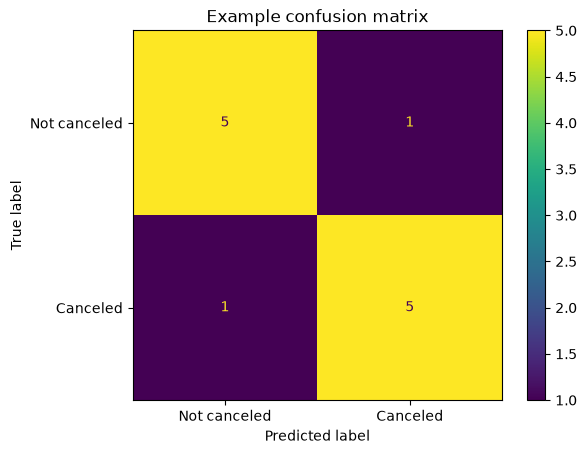

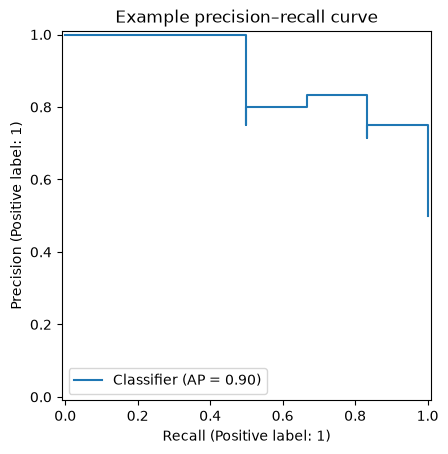

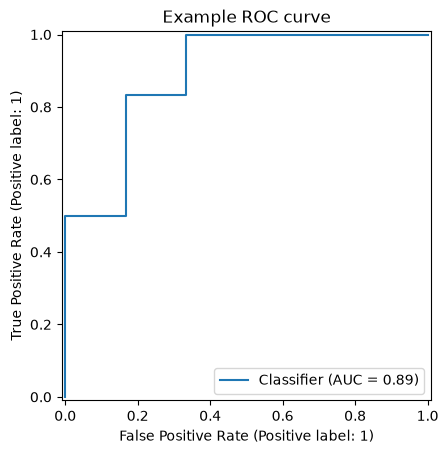

In [26]:
# Optional synthetic illustration — this is NOT project data.
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

example_true = np.array([0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1])
example_proba = np.array([.12, .81, .66, .74, .33, .22, .14, .92, .42, .57, .08, .61])
example_pred = (example_proba >= .5).astype(int)

ConfusionMatrixDisplay.from_predictions(example_true, example_pred,
                                       display_labels=['Not canceled', 'Canceled'])
plt.title('Example confusion matrix')
plt.show()

PrecisionRecallDisplay.from_predictions(example_true, example_proba)
plt.title('Example precision–recall curve')
plt.show()

RocCurveDisplay.from_predictions(example_true, example_proba)
plt.title('Example ROC curve')
plt.show()
